## LaDe 20: Aoi Service Periods And Courier Subregions (Flag 20)

### Dataset Overview

Constructed LaDe-style Shanghai pickup data: 220 tasks, 12 courier-days, 26141 GPS points. All times are local Shanghai time. Task destinations and GPS paths lie on the archived OSM street network; oneway directions are respected, while turn-restriction relations are not modeled. Moving GPS steps preserve all road vertices and have maximum spacing 45 m. speed_kmh and activity_state describe the immediately preceding segment. AOIs are explicitly constructed circular catchments within one constructed region, not original LaDe AOI polygons. Task events, service windows, couriers and assignments are constructed. accept_gps_time is the closest recorded GPS time to task acceptance; acceptance_distance_km uses interpolated position at the exact event time. Pickup GPS is recorded at the actual service-completion position. The last pickup is the observed end of each courier-day. Stationary waiting is retained in the GPS trace, but excluded from active_duration_hours, which sums travelling and servicing time. AOI visit intervals denote access-entry arrival through final pickup/service completion, not exact geometric boundary entry/exit; subsequent exit travel is recorded separately and is not counted as service.

The primary table is loaded into `df`; the supporting GPS table is loaded into `user_df`.

Goal: Analyze pickup activity across local service areas during the workday.

Role: Last-mile logistics analyst


Category: aoi_service_periods_and_courier_subregions


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display

## Load Dataset

The primary table is loaded into `df`; the supporting trajectory table is loaded into `user_df`.

In [ ]:
dataset_path = "pickup_tasks.csv"
df = pd.read_csv(dataset_path)

In [ ]:
user_dataset_path = "courier_trajectories.csv"
user_df = pd.read_csv(user_dataset_path)

### **Question 1**: Do similarly active AOIs have separated or continuous service periods?

#### Analysis action

Reconstruct the comparison from the supplied task, GPS and support tables. Interpret associations descriptively, not as causal effects.

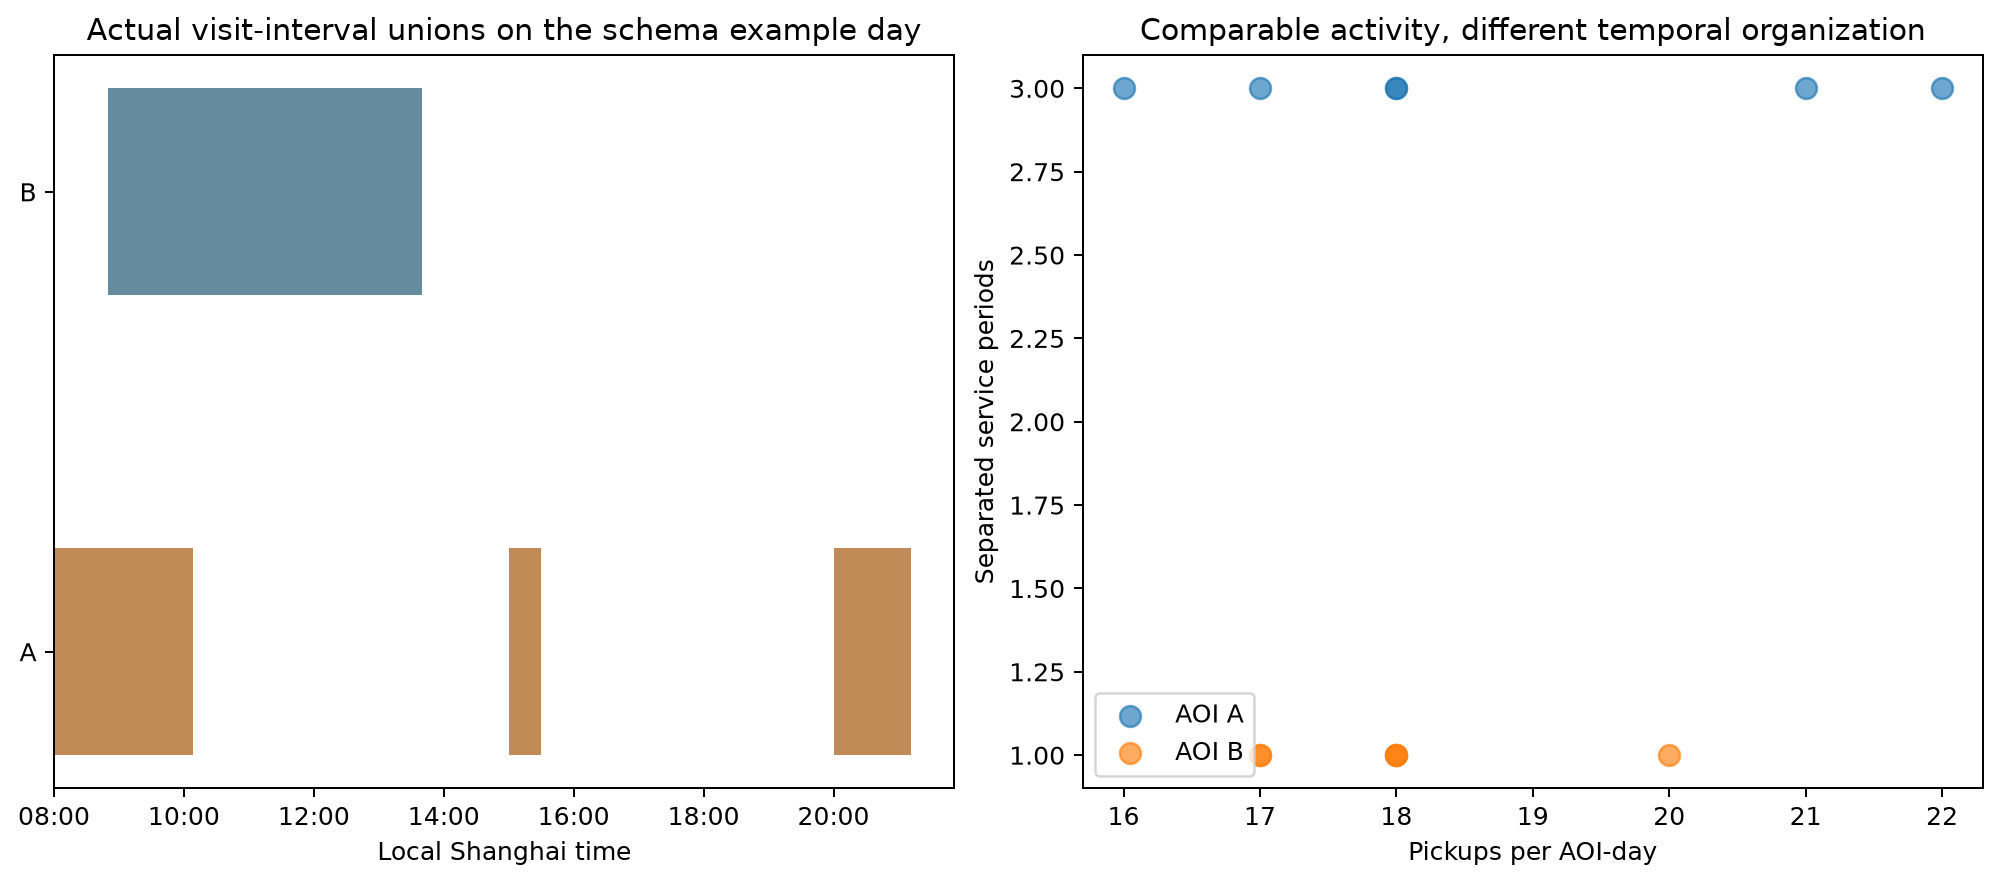

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

supplement = pd.read_csv("aoi_visits.csv")
aois = pd.read_csv("aois.csv")


def aoi_service_periods(df, user_df, supplement, aois):
    import matplotlib.dates as mdates

    rows = []
    for (day, aoi), q in supplement.groupby(["service_date", "aoi_id"]):
        intervals = sorted(
            (pd.Timestamp(r.arrival_time), pd.Timestamp(r.departure_time))
            for r in q.itertuples()
        )
        merged = []
        for start, end in intervals:
            if merged and start <= merged[-1][1]:
                merged[-1][1] = max(merged[-1][1], end)
            else:
                merged.append([start, end])
        duration = sum((b - a).total_seconds() / 60 for a, b in merged)
        rows.append(
            {
                "service_date": day,
                "aoi_id": aoi,
                "periods": len(merged),
                "union_visit_minutes": duration,
                "task_count": len(df[df.service_date.eq(day) & df.aoi_id.eq(aoi)]),
                "intervals": [[str(a), str(b)] for a, b in merged],
            }
        )
    d = pd.DataFrame(rows)
    first = d[d.service_date.eq(d.service_date.min())]
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.8), constrained_layout=True)
    for i, r in enumerate(first.itertuples()):
        for start, end in r.intervals:
            a = mdates.date2num(pd.Timestamp(start))
            b = mdates.date2num(pd.Timestamp(end))
            axes[0].barh(i, b - a, left=a, height=0.45, color=["#c18b57", "#648b9f"][i])
    axes[0].set(
        yticks=range(len(first)),
        yticklabels=first.aoi_id,
        xlabel="Local Shanghai time",
        title="Actual visit-interval unions on the schema example day",
    )
    axes[0].xaxis_date()
    axes[0].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
    for aoi, q in d.groupby("aoi_id"):
        axes[1].scatter(q.task_count, q.periods, label=f"AOI {aoi}", s=70, alpha=0.65)
    axes[1].set(
        xlabel="Pickups per AOI-day",
        ylabel="Separated service periods",
        title="Comparable activity, different temporal organization",
    )
    axes[1].legend()
    return {
        "aoi_days": len(d),
        "mean_task_count_by_aoi": d.groupby("aoi_id").task_count.mean().to_dict(),
        "service_period_counts_by_aoi": (
            d.groupby("aoi_id")
            .periods.apply(lambda s: sorted(s.unique().tolist()))
            .to_dict()
        ),
        "schema_day_intervals": first.to_dict("records"),
    }


evidence = aoi_service_periods(df, user_df, supplement, aois)
print(evidence)
plt.close("all")
plt.close("all")
# Display the verified visualization once.
display(Image(filename="visualizations/insight_1.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Very High (6 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "aoi_service_periods",
  "insight_type": "overall_pattern",
  "insight": "Some AOIs are served in several separated periods during the day, while similarly active AOIs are handled within a much more continous period.",
  "insight_value": {
    "aoi_days": 12,
    "mean_task_count_by_aoi": {
      "A": 18.666666666666668,
      "B": 18.0
    },
    "service_period_counts_by_aoi": {
      "A": [
        3
      ],
      "B": [
        1
      ]
    },
    "schema_day_intervals": [
      {
        "service_date": "2026-08-17",
        "aoi_id": "A",
        "periods": 3,
        "union_visit_minutes": 230.0,
        "task_count": 18,
        "intervals": [
          [
            "2026-08-17 08:00:00",
            "2026-08-17 10:08:00"
          ],
          [
            "2026-08-17 15:00:00",
            "2026-08-17 15:30:00"
          ],
          [
            "2026-08-17 20:00:00",
            "2026-08-17 21:12:00"
          ]
        ]
      },
      {
        "service_date": "2026-08-17",
        "aoi_id": "B",
        "periods": 1,
        "union_visit_minutes": 290.0,
        "task_count": 18,
        "intervals": [
          [
            "2026-08-17 08:50:00",
            "2026-08-17 13:40:00"
          ]
        ]
      }
    ]
  },
  "question": "Do similarly active AOIs have separated or continuous service periods?",
  "actionable_insight": "Reconstruct the comparison from the supplied task, GPS and support tables. Interpret associations descriptively, not as causal effects.",
  "plot": {
    "plot_type": "paired_evidence_panels",
    "title": "Do similarly active AOIs have separated or continuous service periods?",
    "file": "visualizations/insight_1.png",
    "description": "Both panels and all statistics are calculated from the emitted CSV tables."
  },
  "code": "import pandas as pd\nimport numpy as np\nimport matplotlib.pyplot as plt\nsupplement=pd.read_csv(\"aoi_visits.csv\")\naois=pd.read_csv(\"aois.csv\")\n\ndef aoi_service_periods(df,user_df,supplement,aois):\n    import matplotlib.dates as mdates\n    rows=[]\n    for (day,aoi),q in supplement.groupby(['service_date','aoi_id']):\n        intervals=sorted((pd.Timestamp(r.arrival_time),pd.Timestamp(r.departure_time)) for r in q.itertuples());merged=[]\n        for start,end in intervals:\n            if merged and start<=merged[-1][1]:merged[-1][1]=max(merged[-1][1],end)\n            else:merged.append([start,end])\n        duration=sum((b-a).total_seconds()/60 for a,b in merged)\n        rows.append({'service_date':day,'aoi_id':aoi,'periods':len(merged),'union_visit_minutes':duration,\n            'task_count':len(df[df.service_date.eq(day)&df.aoi_id.eq(aoi)]),\n            'intervals':[[str(a),str(b)] for a,b in merged]})\n    d=pd.DataFrame(rows);first=d[d.service_date.eq(d.service_date.min())]\n    fig,axes=plt.subplots(1,2,figsize=(11,4.8),constrained_layout=True)\n    for i,r in enumerate(first.itertuples()):\n        for start,end in r.intervals:\n            a=mdates.date2num(pd.Timestamp(start));b=mdates.date2num(pd.Timestamp(end))\n            axes[0].barh(i,b-a,left=a,height=.45,color=['#c18b57','#648b9f'][i])\n    axes[0].set(yticks=range(len(first)),yticklabels=first.aoi_id,xlabel='Local Shanghai time',title='Actual visit-interval unions on the schema example day')\n    axes[0].xaxis_date();axes[0].xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))\n    for aoi,q in d.groupby('aoi_id'):axes[1].scatter(q.task_count,q.periods,label=f'AOI {aoi}',s=70,alpha=.65)\n    axes[1].set(xlabel='Pickups per AOI-day',ylabel='Separated service periods',title='Comparable activity, different temporal organization');axes[1].legend()\n    return {'aoi_days':len(d),'mean_task_count_by_aoi':d.groupby('aoi_id').task_count.mean().to_dict(),\n            'service_period_counts_by_aoi':d.groupby('aoi_id').periods.apply(lambda s:sorted(s.unique().tolist())).to_dict(),'schema_day_intervals':first.to_dict('records')}\n\nevidence=aoi_service_periods(df,user_df,supplement,aois)\nprint(evidence)\nplt.show()",
  "difficulty_level": 6,
  "difficulty_label": "very high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "aoi_id",
    "pickup_time",
    "task_id",
    "courier_id",
    "gps_position",
    "gps_time"
  ]
}

### **Question 2**: Where do pickups occur within their promised windows at each AOI?

#### Analysis action

Reconstruct the comparison from the supplied task, GPS and support tables. Interpret associations descriptively, not as causal effects.

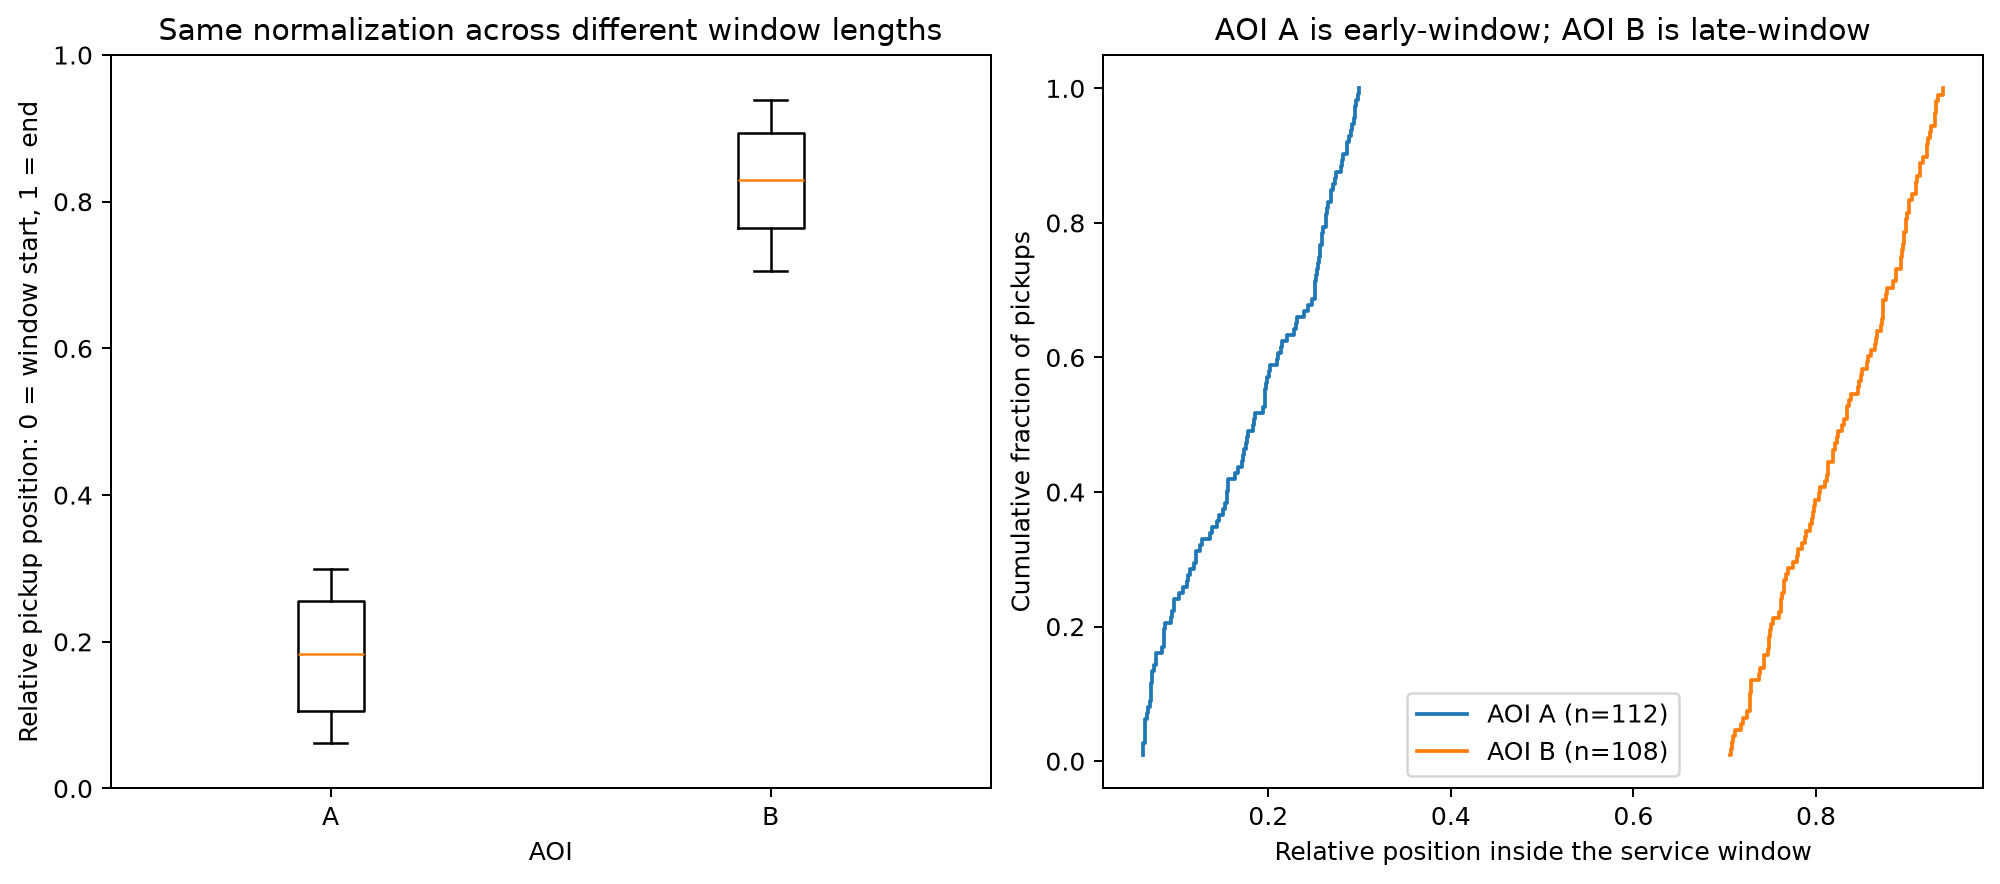

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

supplement = pd.read_csv("aoi_visits.csv")
aois = pd.read_csv("aois.csv")


def window_position(df, user_df, supplement, aois):
    d = df.copy()
    start = pd.to_datetime(d.time_window_start, format="mixed")
    end = pd.to_datetime(d.time_window_end, format="mixed")
    pickup = pd.to_datetime(d.pickup_time, format="mixed")
    d["relative_position"] = (pickup - start).dt.total_seconds() / (
        end - start
    ).dt.total_seconds()
    groups = d.groupby("aoi_id")
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.8), constrained_layout=True)
    axes[0].boxplot(
        [q.relative_position for _, q in groups], tick_labels=[a for a, _ in groups]
    )
    axes[0].set(
        xlabel="AOI",
        ylabel="Relative pickup position: 0 = window start, 1 = end",
        ylim=(0, 1),
        title="Same normalization across different window lengths",
    )
    for aoi, q in groups:
        ordered = np.sort(q.relative_position)
        axes[1].step(
            ordered,
            np.arange(1, len(q) + 1) / len(q),
            where="post",
            label=f"AOI {aoi} (n={len(q)})",
        )
    axes[1].set(
        xlabel="Relative position inside the service window",
        ylabel="Cumulative fraction of pickups",
        title="AOI A is early-window; AOI B is late-window",
    )
    axes[1].legend()
    return {
        "task_counts_by_aoi": groups.size().to_dict(),
        "median_relative_window_position": groups.relative_position.median().to_dict(),
        "within_window_share": float(d.relative_position.between(0, 1).mean()),
        "daily_medians": (
            d.groupby(["service_date", "aoi_id"])
            .relative_position.median()
            .unstack()
            .to_dict()
        ),
    }


evidence = window_position(df, user_df, supplement, aois)
print(evidence)
plt.close("all")
plt.close("all")
# Display the verified visualization once.
display(Image(filename="visualizations/insight_2.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: High (5 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "window_position",
  "insight_type": "overall_pattern",
  "insight": "AOIs with similar task volumes can show different pickup timing relative to their service windows, with some concentrated near window starts and others closer to window ends.",
  "insight_value": {
    "task_counts_by_aoi": {
      "A": 112,
      "B": 108
    },
    "median_relative_window_position": {
      "A": 0.18376415290118522,
      "B": 0.8298459967651568
    },
    "within_window_share": 1.0,
    "daily_medians": {
      "A": {
        "2026-08-17": 0.17354754693691776,
        "2026-08-18": 0.22190097958432564,
        "2026-08-19": 0.18702779930295466,
        "2026-08-20": 0.17880613686446817,
        "2026-08-21": 0.19659647946891895,
        "2026-08-24": 0.1278449715915488
      },
      "B": {
        "2026-08-17": 0.8556348371468491,
        "2026-08-18": 0.7953990460890836,
        "2026-08-19": 0.8399566006695093,
        "2026-08-20": 0.8158827660510444,
        "2026-08-21": 0.8493560706681601,
        "2026-08-24": 0.8534408318823581
      }
    }
  },
  "question": "Where do pickups occur within their promised windows at each AOI?",
  "actionable_insight": "Reconstruct the comparison from the supplied task, GPS and support tables. Interpret associations descriptively, not as causal effects.",
  "plot": {
    "plot_type": "paired_evidence_panels",
    "title": "Where do pickups occur within their promised windows at each AOI?",
    "file": "visualizations/insight_2.png",
    "description": "Both panels and all statistics are calculated from the emitted CSV tables."
  },
  "code": "import pandas as pd\nimport numpy as np\nimport matplotlib.pyplot as plt\nsupplement=pd.read_csv(\"aoi_visits.csv\")\naois=pd.read_csv(\"aois.csv\")\n\ndef window_position(df,user_df,supplement,aois):\n    d=df.copy();start=pd.to_datetime(d.time_window_start,format='mixed');end=pd.to_datetime(d.time_window_end,format='mixed');pickup=pd.to_datetime(d.pickup_time,format='mixed')\n    d['relative_position']=(pickup-start).dt.total_seconds()/(end-start).dt.total_seconds();groups=d.groupby('aoi_id')\n    fig,axes=plt.subplots(1,2,figsize=(11,4.8),constrained_layout=True)\n    axes[0].boxplot([q.relative_position for _,q in groups],tick_labels=[a for a,_ in groups])\n    axes[0].set(xlabel='AOI',ylabel='Relative pickup position: 0 = window start, 1 = end',ylim=(0,1),title='Same normalization across different window lengths')\n    for aoi,q in groups:\n        ordered=np.sort(q.relative_position);axes[1].step(ordered,np.arange(1,len(q)+1)/len(q),where='post',label=f'AOI {aoi} (n={len(q)})')\n    axes[1].set(xlabel='Relative position inside the service window',ylabel='Cumulative fraction of pickups',title='AOI A is early-window; AOI B is late-window');axes[1].legend()\n    return {'task_counts_by_aoi':groups.size().to_dict(),'median_relative_window_position':groups.relative_position.median().to_dict(),\n            'within_window_share':float(d.relative_position.between(0,1).mean()),'daily_medians':d.groupby(['service_date','aoi_id']).relative_position.median().unstack().to_dict()}\n\nevidence=window_position(df,user_df,supplement,aois)\nprint(evidence)\nplt.show()",
  "difficulty_level": 5,
  "difficulty_label": "high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "aoi_id",
    "pickup_time",
    "time_window_start",
    "time_window_end",
    "task_id"
  ]
}

### **Question 3**: Do courier-specific pickup subregions persist despite shared access trajectories?

#### Analysis action

Reconstruct the comparison from the supplied task, GPS and support tables. Interpret associations descriptively, not as causal effects.

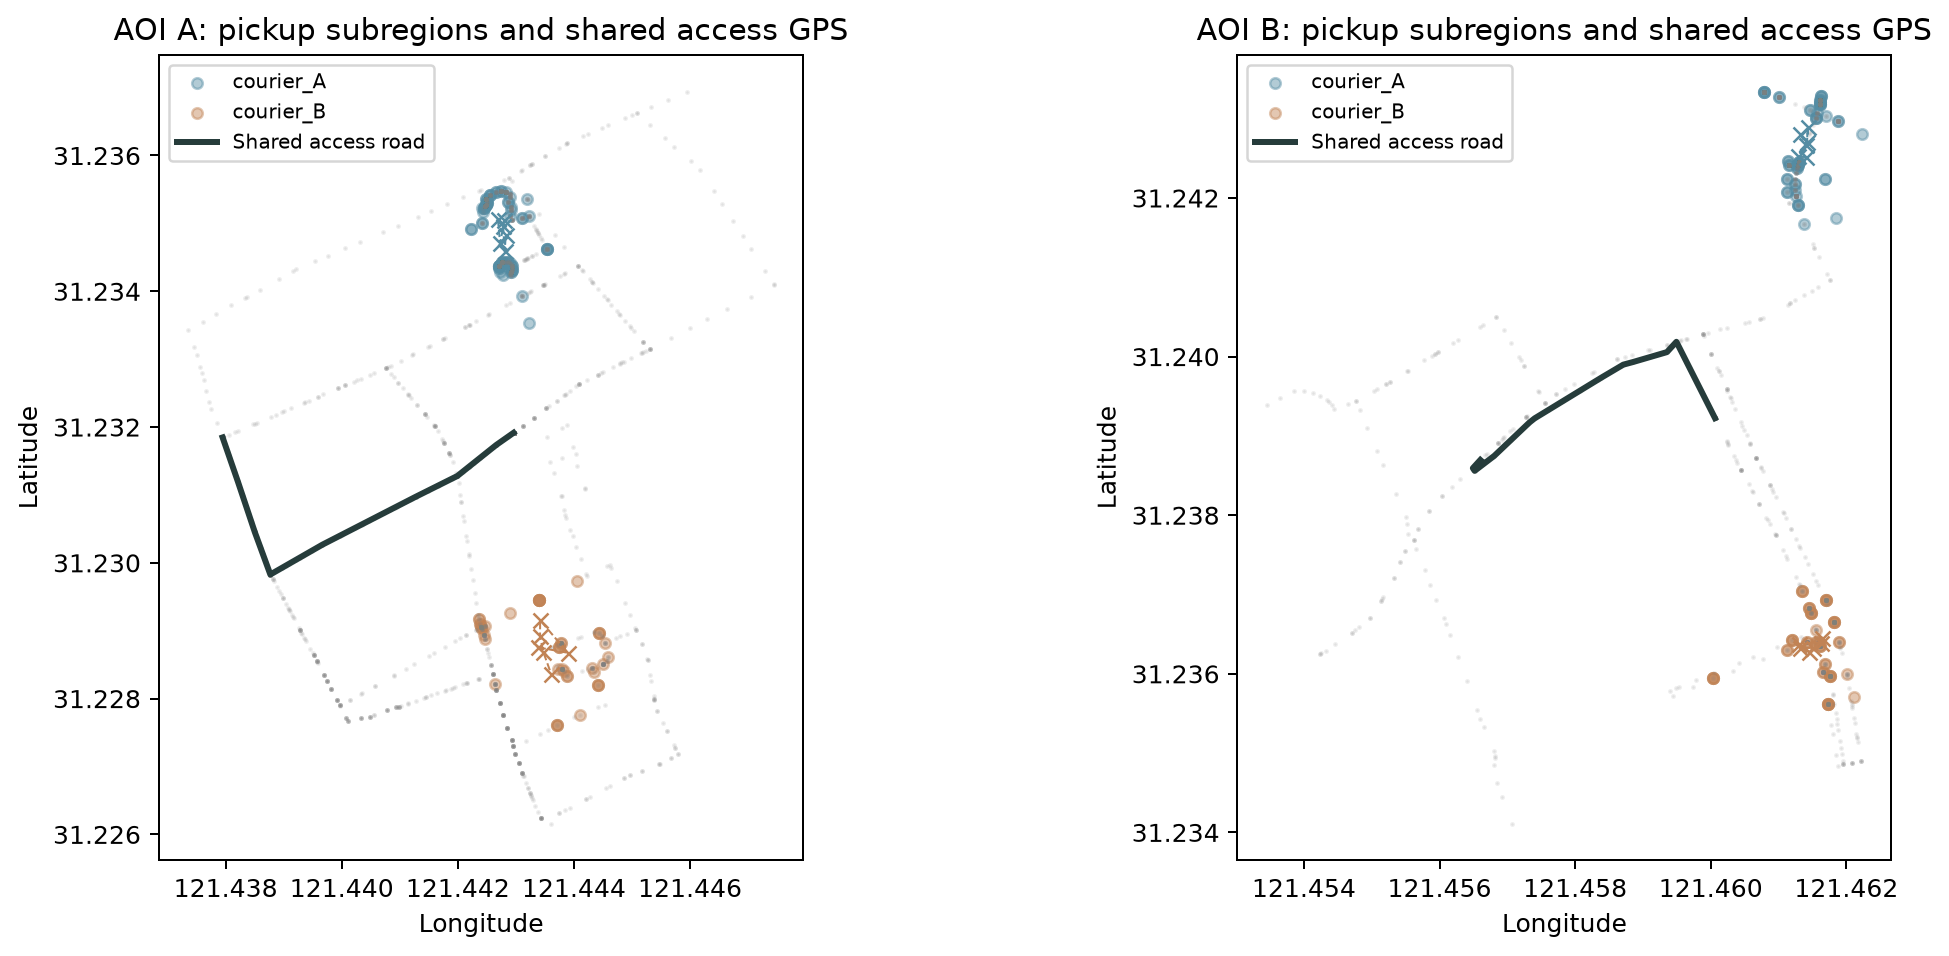

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

supplement = pd.read_csv("aoi_visits.csv")
aois = pd.read_csv("aois.csv")


def persistent_subregions(df, user_df, supplement, aois):
    stats = {}
    fig, axes = plt.subplots(1, 2, figsize=(12, 5.2), constrained_layout=True)
    for ax, (aoi, q) in zip(axes, df.groupby("aoi_id")):
        definition = aois.set_index("aoi_id").loc[aoi]
        center = np.array([definition.center_lng, definition.center_lat])
        scale = np.array([95200, 111000])
        daily = (
            q.groupby(["service_date", "courier_id"])[["pickup_lng", "pickup_lat"]]
            .mean()
            .reset_index()
        )
        correct = []
        shared = []
        for day, heldout in q.groupby("service_date"):
            train = (
                q[q.service_date.ne(day)]
                .groupby("courier_id")[["pickup_lng", "pickup_lat"]]
                .mean()
            )
            x = heldout[["pickup_lng", "pickup_lat"]].to_numpy() * scale
            centroids = train.to_numpy() * scale
            predicted = train.index.to_numpy()[
                np.linalg.norm(x[:, None] - centroids, axis=2).argmin(axis=1)
            ]
            correct.extend(predicted == heldout.courier_id.to_numpy())
            sets = []
            for courier in sorted(q.courier_id.unique()):
                gps = user_df[
                    user_df.service_date.eq(day) & user_df.courier_id.eq(courier)
                ]
                xy = (gps[["lng", "lat"]].to_numpy() - center) * scale
                xy = xy[np.linalg.norm(xy, axis=1) <= definition.radius_m]
                sets.append(set(map(tuple, np.floor(xy / 30).astype(int))))
            shared.append(len(sets[0] & sets[1]))
        separation = np.linalg.norm(
            np.diff(
                q.groupby("courier_id")[["pickup_lng", "pickup_lat"]].mean().to_numpy()
                * scale,
                axis=0,
            )[0]
        )
        for index, (courier, s) in enumerate(q.groupby("courier_id")):
            ax.scatter(
                s.pickup_lng,
                s.pickup_lat,
                s=18,
                alpha=0.45,
                label=courier,
                color=["#548ca3", "#c18355"][index],
            )
            dc = daily[daily.courier_id.eq(courier)]
            ax.plot(
                dc.pickup_lng,
                dc.pickup_lat,
                "x--",
                lw=0.8,
                color=["#548ca3", "#c18355"][index],
            )
        # GPS points near the access corridor expose the shared movement path.
        for courier, gps in user_df[
            user_df.service_date.eq(user_df.service_date.min())
        ].groupby("courier_id"):
            xy = (gps[["lng", "lat"]].to_numpy() - center) * scale
            mask = np.linalg.norm(xy, axis=1) <= definition.radius_m
            ax.scatter(
                gps.loc[mask, "lng"],
                gps.loc[mask, "lat"],
                s=1,
                alpha=0.12,
                color="gray",
            )
        visit = supplement[
            supplement.aoi_id.eq(aoi)
            & supplement.service_date.eq(supplement.service_date.min())
        ].iloc[0]
        access = user_df[
            user_df.trajectory_id.eq(visit.trajectory_id)
            & user_df.route_section.eq(visit.visit_id)
        ].copy()
        access = access[
            pd.to_datetime(access.gps_time, format="mixed")
            >= pd.Timestamp(visit.arrival_time)
        ]
        branch = np.flatnonzero(
            (abs(access.lng - definition.branch_lng) < 1e-9)
            & (abs(access.lat - definition.branch_lat) < 1e-9)
        )[0]
        access = access.iloc[: branch + 1]
        ax.plot(
            access.lng,
            access.lat,
            color="#263c3b",
            lw=2.4,
            zorder=4,
            label="Shared access road",
        )
        ax.set(
            title=f"AOI {aoi}: pickup subregions and shared access GPS",
            xlabel="Longitude",
            ylabel="Latitude",
        )
        ax.ticklabel_format(useOffset=False)
        ax.set_aspect(1 / np.cos(np.radians(center[1])))
        ax.legend(fontsize=8)
        stats[aoi] = {
            "leave_one_day_out_courier_classification_accuracy": float(
                np.mean(correct)
            ),
            "courier_pickup_centroid_separation_m": float(separation),
            "daily_shared_30m_GPS_cells": shared,
            "days": q.service_date.nunique(),
            "couriers": q.courier_id.nunique(),
        }
    return {
        "aoi_evidence": stats,
        "overlap_definition": (
            "Shared 30-metre GPS grid cells inside each constructed AOI; a"
            " sampling-based overlap indicator, not an exact road length."
        ),
    }


evidence = persistent_subregions(df, user_df, supplement, aois)
print(evidence)
plt.close("all")
plt.close("all")
# Display the verified visualization once.
display(Image(filename="visualizations/insight_3.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Very High (7 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "persistent_subregions",
  "insight_type": "factor_relationship",
  "insight": "Within AOIs served by multiple couriers, pickup locations form persistent courier-specific subregions across days, even when their trajectories overlap along common access corridors.",
  "insight_value": {
    "aoi_evidence": {
      "A": {
        "leave_one_day_out_courier_classification_accuracy": 1.0,
        "courier_pickup_centroid_separation_m": 680.4828508210119,
        "daily_shared_30m_GPS_cells": [
          72,
          78,
          79,
          77,
          76,
          77
        ],
        "days": 6,
        "couriers": 2
      },
      "B": {
        "leave_one_day_out_courier_classification_accuracy": 1.0,
        "courier_pickup_centroid_separation_m": 702.8756246050971,
        "daily_shared_30m_GPS_cells": [
          47,
          46,
          48,
          47,
          48,
          49
        ],
        "days": 6,
        "couriers": 2
      }
    },
    "overlap_definition": "Shared 30-metre GPS grid cells inside each constructed AOI; a sampling-based overlap indicator, not an exact road length."
  },
  "question": "Do courier-specific pickup subregions persist despite shared access trajectories?",
  "actionable_insight": "Reconstruct the comparison from the supplied task, GPS and support tables. Interpret associations descriptively, not as causal effects.",
  "plot": {
    "plot_type": "paired_evidence_panels",
    "title": "Do courier-specific pickup subregions persist despite shared access trajectories?",
    "file": "visualizations/insight_3.png",
    "description": "Both panels and all statistics are calculated from the emitted CSV tables."
  },
  "code": "import pandas as pd\nimport numpy as np\nimport matplotlib.pyplot as plt\nsupplement=pd.read_csv(\"aoi_visits.csv\")\naois=pd.read_csv(\"aois.csv\")\n\ndef persistent_subregions(df,user_df,supplement,aois):\n    stats={};fig,axes=plt.subplots(1,2,figsize=(12,5.2),constrained_layout=True)\n    for ax,(aoi,q) in zip(axes,df.groupby('aoi_id')):\n        definition=aois.set_index('aoi_id').loc[aoi];center=np.array([definition.center_lng,definition.center_lat]);scale=np.array([95200,111000])\n        daily=q.groupby(['service_date','courier_id'])[['pickup_lng','pickup_lat']].mean().reset_index()\n        correct=[];shared=[]\n        for day,heldout in q.groupby('service_date'):\n            train=q[q.service_date.ne(day)].groupby('courier_id')[['pickup_lng','pickup_lat']].mean()\n            x=heldout[['pickup_lng','pickup_lat']].to_numpy()*scale;centroids=train.to_numpy()*scale\n            predicted=train.index.to_numpy()[np.linalg.norm(x[:,None]-centroids,axis=2).argmin(axis=1)]\n            correct.extend(predicted==heldout.courier_id.to_numpy());sets=[]\n            for courier in sorted(q.courier_id.unique()):\n                gps=user_df[user_df.service_date.eq(day)&user_df.courier_id.eq(courier)]\n                xy=(gps[['lng','lat']].to_numpy()-center)*scale;xy=xy[np.linalg.norm(xy,axis=1)<=definition.radius_m]\n                sets.append(set(map(tuple,np.floor(xy/30).astype(int))))\n            shared.append(len(sets[0]&sets[1]))\n        separation=np.linalg.norm(np.diff(q.groupby('courier_id')[['pickup_lng','pickup_lat']].mean().to_numpy()*scale,axis=0)[0])\n        for index,(courier,s) in enumerate(q.groupby('courier_id')):\n            ax.scatter(s.pickup_lng,s.pickup_lat,s=18,alpha=.45,label=courier,color=['#548ca3','#c18355'][index])\n            dc=daily[daily.courier_id.eq(courier)];ax.plot(dc.pickup_lng,dc.pickup_lat,'x--',lw=.8,color=['#548ca3','#c18355'][index])\n        # GPS points near the access corridor expose the shared movement path.\n        for courier,gps in user_df[user_df.service_date.eq(user_df.service_date.min())].groupby('courier_id'):\n            xy=(gps[['lng','lat']].to_numpy()-center)*scale;mask=np.linalg.norm(xy,axis=1)<=definition.radius_m\n            ax.scatter(gps.loc[mask,'lng'],gps.loc[mask,'lat'],s=1,alpha=.12,color='gray')\n        visit=supplement[supplement.aoi_id.eq(aoi)&supplement.service_date.eq(supplement.service_date.min())].iloc[0]\n        access=user_df[user_df.trajectory_id.eq(visit.trajectory_id)&user_df.route_section.eq(visit.visit_id)].copy()\n        access=access[pd.to_datetime(access.gps_time,format='mixed')>=pd.Timestamp(visit.arrival_time)]\n        branch=np.flatnonzero((abs(access.lng-definition.branch_lng)<1e-9)&(abs(access.lat-definition.branch_lat)<1e-9))[0]\n        access=access.iloc[:branch+1]\n        ax.plot(access.lng,access.lat,color='#263c3b',lw=2.4,zorder=4,label='Shared access road')\n        ax.set(title=f'AOI {aoi}: pickup subregions and shared access GPS',xlabel='Longitude',ylabel='Latitude');ax.ticklabel_format(useOffset=False)\n        ax.set_aspect(1/np.cos(np.radians(center[1])));ax.legend(fontsize=8)\n        stats[aoi]={'leave_one_day_out_courier_classification_accuracy':float(np.mean(correct)),\n            'courier_pickup_centroid_separation_m':float(separation),'daily_shared_30m_GPS_cells':shared,\n            'days':q.service_date.nunique(),'couriers':q.courier_id.nunique()}\n    return {'aoi_evidence':stats,'overlap_definition':'Shared 30-metre GPS grid cells inside each constructed AOI; a sampling-based overlap indicator, not an exact road length.'}\n\nevidence=persistent_subregions(df,user_df,supplement,aois)\nprint(evidence)\nplt.show()",
  "difficulty_level": 7,
  "difficulty_label": "very high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "courier_id",
    "aoi_id",
    "pickup_time",
    "task_position",
    "gps_time",
    "gps_position",
    "task_id"
  ]
}

### Summary of Findings (Flag 20)

Some AOIs are served in several separated periods during the day, while similarly active AOIs are handled within a much more continous period. AOIs with similar task volumes can show different pickup timing relative to their service windows, with some concentrated near window starts and others closer to window ends. Within AOIs served by multiple couriers, pickup locations form persistent courier-specific subregions across days, even when their trajectories overlap along common access corridors.